# 不计分实验：决策树

在本笔记本中，你将可视化一个决策树如何使用信息增益进行划分。

我们将重新审视视频课程中使用的数据集。该数据集是：

正如你在课程中所看到的，在决策树中，我们通过查看某次划分将给我们带来的**信息增益**，来决定一个节点是否会被划分。（视频中 IG 的图像）

其中

$$\text{Information Gain} = H(p_1^\text{node})- \left(w^{\text{left}}H\left(p_1^\text{left}\right) + w^{\text{right}}H\left(p_1^\text{right}\right)\right),$$

且 $H$ 是熵，定义为

$$H(p_1) = -p_1 \text{log}_2(p_1) - (1- p_1) \text{log}_2(1- p_1)$$

记住这里的对数以 2 为底。运行下面的代码块，亲自看看熵 $H(p)$ 在 $p$ 变化时的表现。

请注意，H 在 $p = 0.5$ 时取得其较高值。这意味着事件的概率为 $0.5$。它的最小值在 $p = 0$ 和 $p = 1$ 处取得，即事件发生的概率是完全可预测的。因此，熵展示了一个事件的可预测程度。

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from utils import *

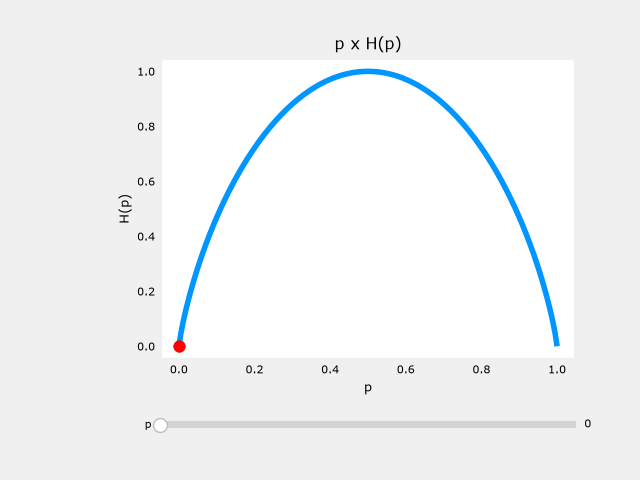

In [2]:
%matplotlib widget
_ = plot_entropy()


|                                                     |   耳朵形状 | 脸型 | 胡须 |   猫  |
|:---------------------------------------------------:|:---------:|:-----------:|:---------:|:------:|
| <img src="images/0.png" alt="drawing" width="50"/> |   尖   |   圆     |  有  |    1   |
| <img src="images/1.png" alt="drawing" width="50"/> |   垂   |  不圆  |  有  |    1   |
| <img src="images/2.png" alt="drawing" width="50"/> |   垂   |  圆      |  无   |    0   |
| <img src="images/3.png" alt="drawing" width="50"/> |   尖   |  不圆  |  有  |    0   |
| <img src="images/4.png" alt="drawing" width="50"/> |   尖   |   圆     |  有  |    1   |
| <img src="images/5.png" alt="drawing" width="50"/> |   尖   |   圆     |  无   |    1   |
| <img src="images/6.png" alt="drawing" width="50"/> |   垂   |  不圆  |  无   |    0   |
| <img src="images/7.png" alt="drawing" width="50"/> |   尖   |  圆      |  无   |    1   |
| <img src="images/8.png" alt="drawing" width="50"/> |    垂  |   圆     |  无   |    0   |
| <img src="images/9.png" alt="drawing" width="50"/> |   垂   |  圆      |  无   |    0   |


我们将使用 **one-hot 编码** 来编码这些类别特征。它们将如下所示：

- 耳朵形状：尖 = 1，垂 = 0
- 脸型：圆 = 1，不圆 = 0
- 胡须：有 = 1，无 = 0

因此，我们有两个集合：

- `X_train`：对于每个样本，包含 3 个特征：
            - 耳朵形状（尖为 1，否则为 0）
            - 脸型（圆为 1，否则为 0）
            - 胡须（有为 1，否则为 0）

- `y_train`：该动物是否是猫
            - 如果该动物是猫则为 1
            - 否则为 0

In [3]:
X_train = np.array([[1, 1, 1],
[0, 0, 1],
 [0, 1, 0],
 [1, 0, 1],
 [1, 1, 1],
 [1, 1, 0],
 [0, 0, 0],
 [1, 1, 0],
 [0, 1, 0],
 [0, 1, 0]])

y_train = np.array([1, 1, 0, 0, 1, 1, 0, 1, 0, 0])

In [4]:
#For instance, the first example
X_train[0]

array([1, 1, 1])

这意味着第一个样本有尖的耳朵形状、圆的脸型，并且它有胡须。

在每个节点上，我们为每个特征计算信息增益，然后通过比较该节点的熵与两个划分后节点中的加权熵，在信息增益更高的特征上划分该节点。

所以，根节点包含我们数据集中的每一只动物。记住 $p_1^{node}$ 是根节点中正类（猫）所占的比例。所以

$$p_1^{node} = \frac{5}{10} = 0.5$$

现在让我们编写一个函数来计算熵。

In [5]:
def entropy(p):
    if p == 0 or p == 1:
        return 0
    else:
        return -p * np.log2(p) - (1- p)*np.log2(1 - p)
    
print(entropy(0.5))

1.0


为了说明，让我们计算如果对每个特征划分该节点所得到的信息增益。为此，让我们编写一些函数。

In [6]:
def split_indices(X, index_feature):
    """Given a dataset and a index feature, return two lists for the two split nodes, the left node has the animals that have 
    that feature = 1 and the right node those that have the feature = 0 
    index feature = 0 => ear shape
    index feature = 1 => face shape
    index feature = 2 => whiskers
    """
    left_indices = []
    right_indices = []
    for i,x in enumerate(X):
        if x[index_feature] == 1:
            left_indices.append(i)
        else:
            right_indices.append(i)
    return left_indices, right_indices

所以，如果我们选择耳朵形状来划分，那么左节点中（对照上表）必须有这些索引：

$$0 \quad 3 \quad 4 \quad 5 \quad 7$$

而右索引则是剩下的那些。

In [7]:
split_indices(X_train, 0)

([0, 3, 4, 5, 7], [1, 2, 6, 8, 9])

现在我们需要另一个函数来计算划分后节点中的加权熵。正如你在视频课程中所看到的，我们必须求出：

- $w^{\text{left}}$ 和 $w^{\text{right}}$，即**每个节点**中动物所占的比例。
- $p^{\text{left}}$ 和 $p^{\text{right}}$，即**每个划分**中猫所占的比例。

注意这两个定义之间的区别！！为了说明，如果我们在索引为 0 的特征（耳朵形状）上划分根节点，那么在左节点中——即拥有动物 0、3、4、5 和 7 的那个——我们有：

$$w^{\text{left}}= \frac{5}{10} = 0.5 \text{ and } p^{\text{left}} = \frac{4}{5}$$
$$w^{\text{right}}= \frac{5}{10} = 0.5 \text{ and } p^{\text{right}} = \frac{1}{5}$$

In [8]:
def weighted_entropy(X,y,left_indices,right_indices):
    """
    This function takes the splitted dataset, the indices we chose to split and returns the weighted entropy.
    """
    w_left = len(left_indices)/len(X)
    w_right = len(right_indices)/len(X)
    p_left = sum(y[left_indices])/len(left_indices)
    p_right = sum(y[right_indices])/len(right_indices)
    
    weighted_entropy = w_left * entropy(p_left) + w_right * entropy(p_right)
    return weighted_entropy

In [9]:
left_indices, right_indices = split_indices(X_train, 0)
weighted_entropy(X_train, y_train, left_indices, right_indices)

np.float64(0.7219280948873623)

所以，2 个划分节点中的加权熵是 0.72。要计算**信息增益**，我们必须把它从我们选择划分的那个节点（本例中是根节点）的熵中减去。

In [10]:
def information_gain(X, y, left_indices, right_indices):
    """
    Here, X has the elements in the node and y is theirs respectives classes
    """
    p_node = sum(y)/len(y)
    h_node = entropy(p_node)
    w_entropy = weighted_entropy(X,y,left_indices,right_indices)
    return h_node - w_entropy

In [11]:
information_gain(X_train, y_train, left_indices, right_indices)

np.float64(0.2780719051126377)

现在，让我们计算如果对每个特征划分根节点所得到的信息增益：

In [12]:
for i, feature_name in enumerate(['Ear Shape', 'Face Shape', 'Whiskers']):
    left_indices, right_indices = split_indices(X_train, i)
    i_gain = information_gain(X_train, y_train, left_indices, right_indices)
    print(f"Feature: {feature_name}, information gain if we split the root node using this feature: {i_gain:.2f}")
    

Feature: Ear Shape, information gain if we split the root node using this feature: 0.28
Feature: Face Shape, information gain if we split the root node using this feature: 0.03
Feature: Whiskers, information gain if we split the root node using this feature: 0.12


所以，用于划分的最佳特征确实是耳朵形状。运行下面的代码来看划分的实际效果。你不需要理解下面的代码块。

 Depth 0, Root: Split on feature: 0
 - Left leaf node with indices [0, 3, 4, 5, 7]
 - Right leaf node with indices [1, 2, 6, 8, 9]


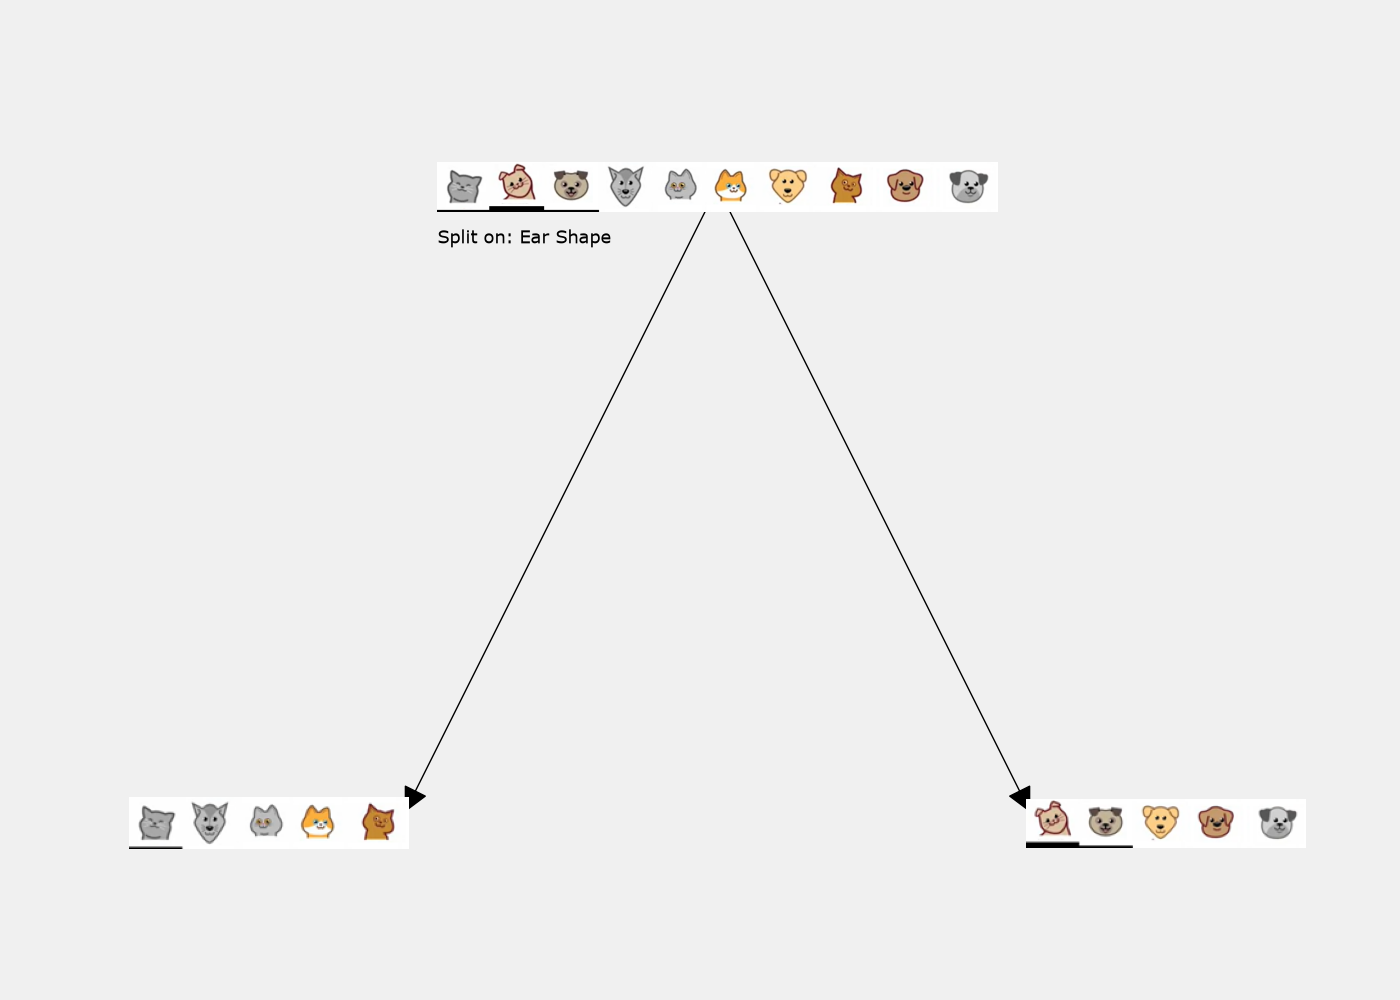

In [13]:
tree = []
build_tree_recursive(X_train, y_train, [0,1,2,3,4,5,6,7,8,9], "Root", max_depth=1, current_depth=0, tree = tree)
generate_tree_viz([0,1,2,3,4,5,6,7,8,9], y_train, tree)

这个过程是**递归的**，这意味着我们必须对每个节点执行这些计算，直到满足某个停止条件：

- 如果划分后的树深度超过某个阈值
- 如果得到的节点只有 1 个类别
- 如果划分的信息增益低于某个阈值

最终的树看起来像这样：

 Depth 0, Root: Split on feature: 0
- Depth 1, Left: Split on feature: 1
  -- Left leaf node with indices [0, 4, 5, 7]
  -- Right leaf node with indices [3]
- Depth 1, Right: Split on feature: 2
  -- Left leaf node with indices [1]
  -- Right leaf node with indices [2, 6, 8, 9]


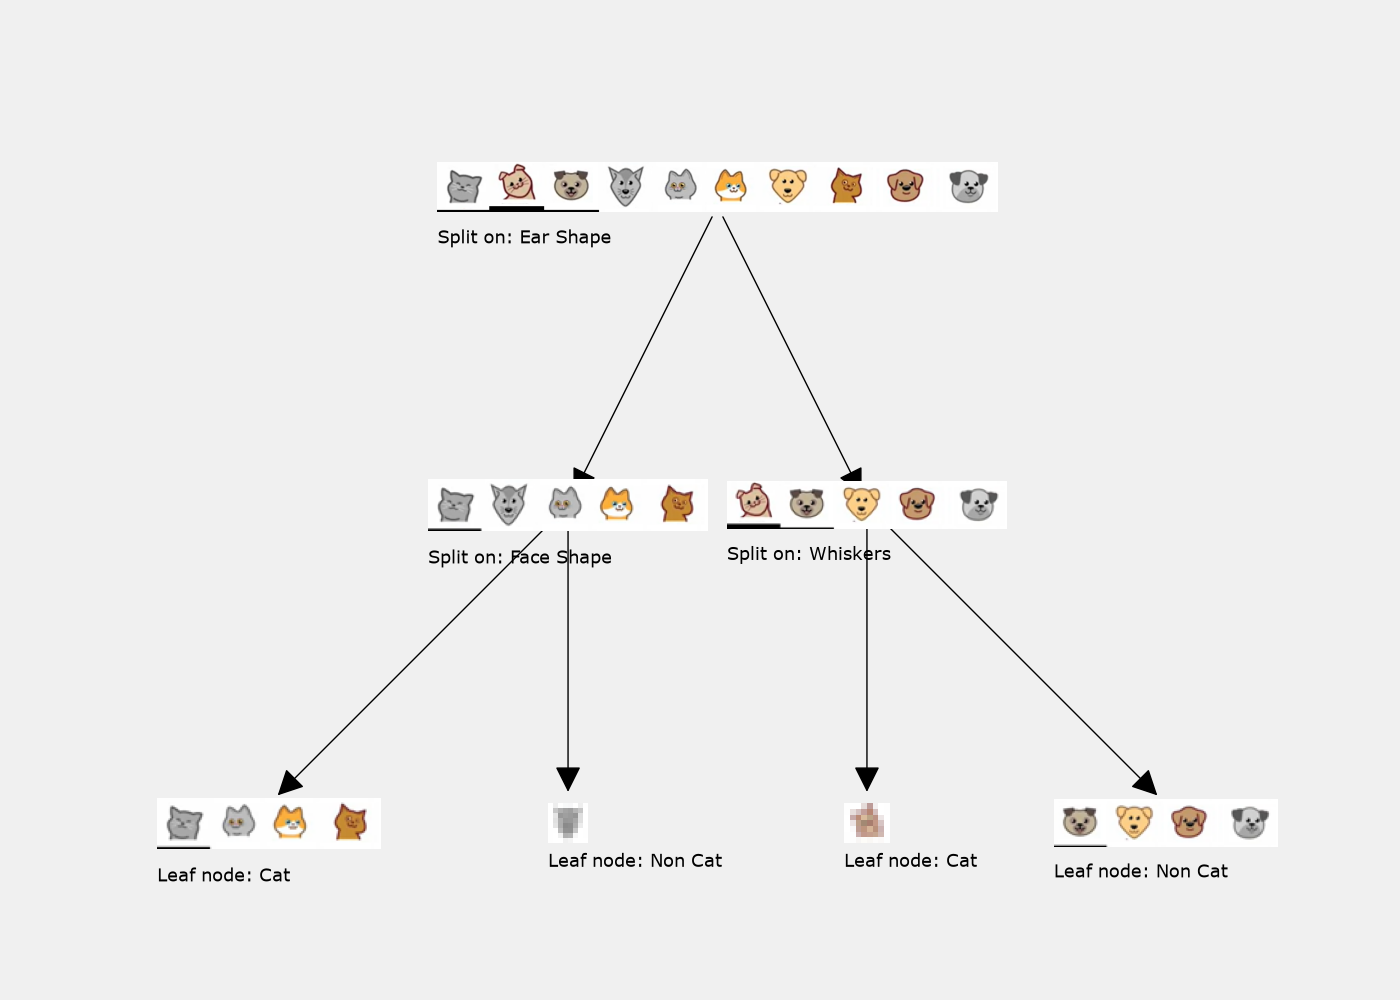

In [14]:
tree = []
build_tree_recursive(X_train, y_train, [0,1,2,3,4,5,6,7,8,9], "Root", max_depth=2, current_depth=0, tree = tree)
generate_tree_viz([0,1,2,3,4,5,6,7,8,9], y_train, tree)

恭喜！你完成了本笔记本！